In [15]:
%pylab inline
import os
import gc
import matplotlib
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTab
import massmap_utilities as mutilities
from configparser import ConfigParser
from pixel3D import cartesianGrid3D
from scipy.stats import norm as statnorm
import matplotlib as mpl

Populating the interactive namespace from numpy and matplotlib


In [2]:
configName  =   '/home/xiangchong/work/gw_ipmu/work/galSim-HSC/s19/s19-1/config-nl1.ini'
parser      =   ConfigParser()
parser.read(configName)
outDir      =   '/home/xiangchong/work/gw_ipmu/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/densityMap/'
inDir       =   '/home/xiangchong/work/gw_ipmu/work/massMapSparse/s19/reGaus_catalog/'

In [3]:
extList={}
for fieldname in mutilities.field_names:
    infname=os.path.join(inDir,'%s.fits'%fieldname )
    data=pyfits.getdata(infname)
    aveWeight=np.average(data['weight'])
    if fieldname=='VVDS':
        addR=(data['ra']<300.).astype(int)*360
        data['ra']+=addR
    #head=pyfits.getheader(infname,ext=1)
    raMin=(np.min(data['ra'])-.1)*60.
    raMax=(np.max(data['ra'])+.1)*60.
    decMin=(np.min(data['dec'])-.1)*60.
    decMax=(np.max(data['dec'])+.1)*60.
    ext=(raMin/60.,raMax/60.,decMin/60.,decMax/60.)
    extList.update({fieldname:ext})
    continue
    nx=int((raMax-raMin+1)//2*2)
    ny=int((decMax-decMin+1)//2*2)
    print(nx,ny)
    parser.set('transPlane','xmin','%s'%raMin)
    parser.set('transPlane','ymin','%s'%decMin)
    parser.set('transPlane','nx','%d'%nx)
    parser.set('transPlane','ny','%d'%ny)
    gridInfo    =   cartesianGrid3D(parser)
    x,y,z=data['ra'],data['dec'],data['dnn_zbest']
    ws=data['weight']
    # w*g1,w*g2,w for each pixel
    weightOutTmp=numpy.histogramdd((z,y,x),bins=(gridInfo.zbound,gridInfo.ybound,gridInfo.xbound))[0]
    mask0=weightOutTmp>0. # the mask before smoothing
    assert weightOutTmp.shape==gridInfo.shape,'the output shape is different from expectation?'
    # variance
    sigma2=np.zeros(gridInfo.shape)
    sigma2[mask0]=1./weightOutTmp[mask0]
    if gridInfo.sigma>0:
        # Gaussian Kernel in Fourier space (normalized in configuration space)
        gausKer=haloSim.GausAtom(ny=ny,nx=nx,sigma=gridInfo.sigma/gridInfo.delta,fou=True,lnorm=2.)
        norm=gausKer[0,0]
        gausKer/=norm
        # smothing with Gausian Kernel
        weightOut=np.fft.ifft2(np.fft.fft2(weightOutTmp)*gausKer).real
    else:
        weightOut=weightOutTmp
    pyfits.writeto(os.path.join(outDir,'%s_numMap.fits' %fieldname),weightOut,overwrite=True)
    del weightOut
    gc.collect()

In [12]:
pltList=['XMM','VVDS','GAMA09H','GAMA15H','WIDE12H','HECTOMAP']
lenList={}
imgList={}
cmax=0.
for fieldname in pltList:
    data=pyfits.getdata(os.path.join(outDir,'%s_numMap.fits' %fieldname))
    print(fieldname)
    print(data.shape)
    lenList.update({fieldname:data.shape})
    imgList.update({fieldname:data})
    fmax=np.max(data)
    if fmax>cmax:
        cmax=fmax

XMM
(1, 324, 632)
VVDS
(1, 422, 1976)
GAMA09H
(1, 408, 1508)
GAMA15H
(1, 194, 1188)
WIDE12H
(1, 394, 2752)
HECTOMAP
(1, 144, 2270)


In [13]:
print(cmax)

75.0


In [26]:
psfs=astTab.Table.read('wrkDir/s19/s19-1/info_newS19Mask_fd001_sim.csv')
ra=psfs['psf_ra']
dec=psfs['psf_dec']

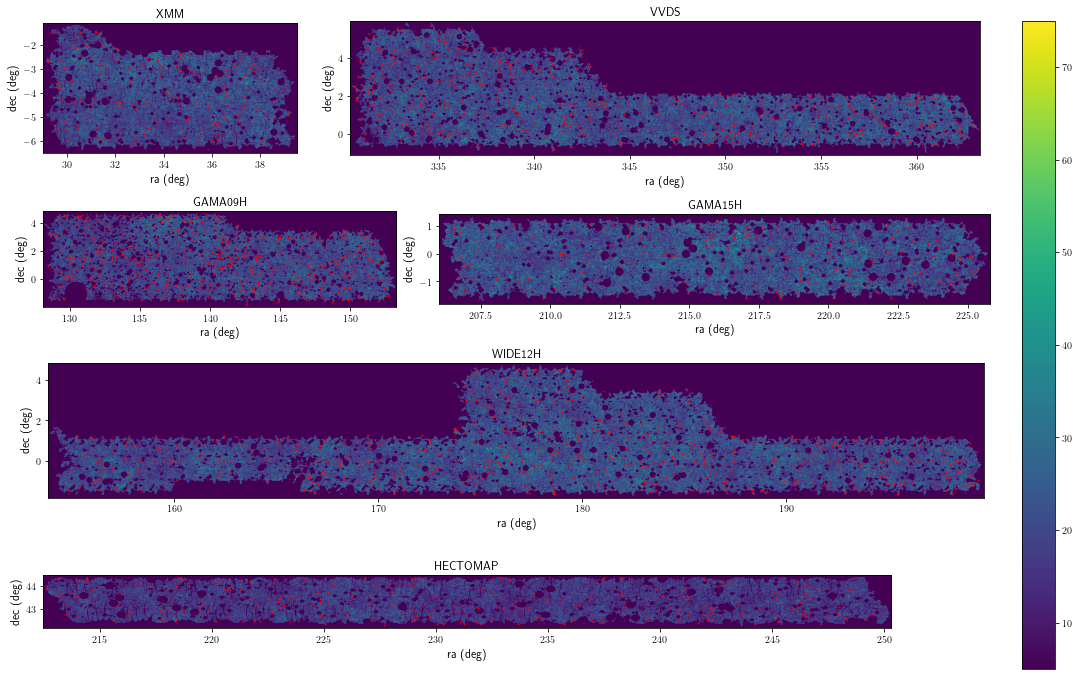

In [37]:
plt.close()
#norm = mpl.colors.SymLogNorm(linthresh=0.4,vmin=5, vmax=cmax)
norm=mpl.colors.Normalize(vmin=5, vmax=cmax)

fig = plt.figure(figsize=(15,10))
ratio=int(1./(lenList['VVDS'][-1]/lenList['VVDS'][-2]/lenList['XMM'][-1]*lenList['XMM'][-2]+1.)*10.+0.5)
ax1 = plt.subplot2grid((8, 10), (0, 0), colspan=ratio,rowspan=2)
ax1.set_title('XMM',fontsize=12)
msk=psfs['field']=='XMM'
ax1.scatter(ra[msk],dec[msk],s=.6,c='red')
ax1.imshow(imgList['XMM'][0],origin='lower',extent=extList['XMM'],norm=norm)
ax1.set_xlabel('ra (deg)',fontsize=12)
ax1.set_ylabel('dec (deg)',fontsize=12)
ax2 = plt.subplot2grid((8, 10), (0, ratio), colspan=10-ratio,rowspan=2)
ax2.set_title('VVDS',fontsize=12)
msk=psfs['field']=='VVDS'
addR=(ra<300.).astype(int)*360
ax2.scatter(ra[msk]+addR[msk],dec[msk],s=.6,c='red')
ax2.imshow(imgList['VVDS'][0],origin='lower',extent=extList['VVDS'],norm=norm)
ax2.set_xlabel('ra (deg)',fontsize=12)
ax2.set_ylabel('dec (deg)',fontsize=12)

ratio=int(1./(lenList['GAMA15H'][-1]/lenList['GAMA15H'][-2]/lenList['GAMA09H'][-1]*lenList['GAMA09H'][-2]+1.)*10.+0.5)
ax3 = plt.subplot2grid((8, 10), (2, 0), colspan=ratio,rowspan=2)
ax3.set_title('GAMA09H',fontsize=12)
msk=psfs['field']=='GAMA09H'
ax3.scatter(ra[msk],dec[msk],s=.6,c='red')
ax3.imshow(imgList['GAMA09H'][0],origin='lower',extent=extList['GAMA09H'],norm=norm)
ax3.set_xlabel('ra (deg)',fontsize=12)
ax3.set_ylabel('dec (deg)',fontsize=12)
ax4 = plt.subplot2grid((8, 10), (2, ratio), colspan=10-ratio,rowspan=2)
ax4.set_title('GAMA15H',fontsize=12)
msk=psfs['field']=='GAMA15H'
ax4.scatter(ra[msk],dec[msk],s=.6,c='red')
ax4.imshow(imgList['GAMA15H'][0],origin='lower',extent=extList['GAMA15H'],norm=norm)
ax4.set_xlabel('ra (deg)',fontsize=12)
ax4.set_ylabel('dec (deg)',fontsize=12)

ax5 = plt.subplot2grid((8, 10), (4, 0), colspan=10,rowspan=2)
ax5.set_title('WIDE12H',fontsize=12)
msk=psfs['field']=='WIDE12H'
ax5.scatter(ra[msk],dec[msk],s=.6,c='red')
ax5.imshow(imgList['WIDE12H'][0],origin='lower',extent=extList['WIDE12H'],norm=norm)
ax5.set_xlabel('ra (deg)',fontsize=12)
ax5.set_ylabel('dec (deg)',fontsize=12)

ax6 = plt.subplot2grid((8, 10), (6, 0), colspan=9,rowspan=2)
ax6.set_title('HECTOMAP',fontsize=12)
msk=psfs['field']=='HECTOMAP'
ax6.scatter(ra[msk],dec[msk],s=.6,c='red')
mm=ax6.imshow(imgList['HECTOMAP'][0],origin='lower',extent=extList['HECTOMAP'],norm=norm)
ax6.set_xlabel('ra (deg)',fontsize=12)
ax6.set_ylabel('dec (deg)',fontsize=12)
plt.tight_layout()
plt.subplots_adjust(bottom=0.05, right=0.92, top=0.95)
cax = plt.axes([0.95, 0.05, 0.03, 0.9])
plt.colorbar(mm,cax=cax)
fig.savefig(os.path.join(outDir,'densityMap.eps'))
fig.savefig(os.path.join(outDir,'densityMap.png'))